# Data Construction Notebook

This notebook documents the workflow used to build full_rent_features.csv. Some cells require external geospatial source files, API access, and GIS libraries; the processed CSV is included for the final analysis notebooks.

In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import box
from shapely.geometry import Point
import requests
import time

import warnings
warnings.filterwarnings('ignore')

## Residential Parcel Selection

Filter SanGIS parcel and land-use data to the UCSD-adjacent study area.

In [3]:
xmin, y_min, x_max, y_max = gpd.GeoSeries([box(-117.268, 32.847, -117.181, 32.896)], 
                                          crs=4326).to_crs(2230).total_bounds

parcels = gpd.read_file(
    "data/parcels/Parcels_South.shp",
    bbox=box(xmin, y_min, x_max, y_max)
)
parcels = parcels[parcels.is_valid]

communities = gpd.read_file("data/communities/Community_Points.shp")
study_area = communities[(communities['community'] == 'La Jolla Village')|
    (communities['community'] == 'University City')]

study_area['geometry'] = study_area.buffer(5000)

study_parcels = gpd.sjoin(parcels, study_area, predicate='intersects').drop(columns=['index_right'])

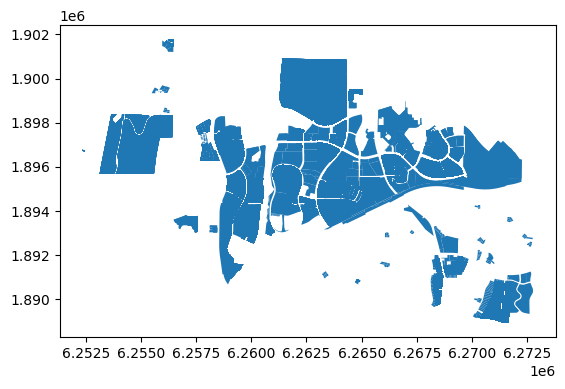

In [4]:
land_use = gpd.read_file(
    "data/landuse/Land_Use_2024.shp",
    where="DESCRIPTIO = 'Single-Family Detached' OR DESCRIPTIO = 'Single Family Multiple-Units' OR\
    DESCRIPTIO = 'Multi-Family Residential'",
    bbox=box(xmin, y_min, x_max, y_max)
)

study_land = gpd.sjoin(study_parcels, land_use, predicate='intersects')
study_land = study_land[['community', 'DESCRIPTIO', 'geometry']].reset_index(drop=True)
study_land.plot();

In [5]:
study_land['centroid'] = study_land.geometry.centroid
study_land.head(20)

,community,DESCRIPTIO,geometry,centroid
0,University City,Single Family Multiple-Units,"POLYGON Z ((6266679.555 1897119.923 0, 6266547...",POINT (6266500.965 1896823.576)
1,University City,Multi-Family Residential,"POLYGON Z ((6266679.555 1897119.923 0, 6266547...",POINT (6266500.965 1896823.576)
2,La Jolla Village,Multi-Family Residential,"POLYGON Z ((6263822.268 1897559.462 0, 6263788...",POINT (6263751.189 1897679.739)
3,La Jolla Village,Multi-Family Residential,"POLYGON Z ((6259544.24 1897416.029 0, 6259313....",POINT (6259424.355 1897491.874)
4,La Jolla Village,Single Family Multiple-Units,"POLYGON Z ((6256172 1901724 0, 6256243 1901674...",POINT (6256247.202 1901608.579)
5,La Jolla Village,Single Family Multiple-Units,"POLYGON Z ((6256172 1901724 0, 6256243 1901674...",POINT (6256247.202 1901608.579)
6,La Jolla Village,Single Family Multiple-Units,"POLYGON Z ((6256172 1901724 0, 6256243 1901674...",POINT (6256247.202 1901608.579)
7,La Jolla Village,Single Family Multiple-Units,"POLYGON Z ((6256172 1901724 0, 6256243 1901674...",POINT (6256247.202 1901608.579)
8,La Jolla Village,Single Family Multiple-Units,"POLYGON Z ((6256172 1901724 0, 6256243 1901674...",POINT (6256247.202 1901608.579)
9,La Jolla Village,Single Family Multiple-Units,"POLYGON Z ((6256172 1901724 0, 6256243 1901674...",POINT (6256247.202 1901608.579)


## Sampling Grid

Create a spatial grid and sampled centroids for collecting rental estimates.

In [6]:
def create_grid(gdf, cell_size):
    minx, miny, maxx, maxy = gdf.total_bounds

    xs = np.arange(minx, maxx, cell_size)
    ys = np.arange(miny, maxy, cell_size)

    polygons = []
    for x in xs:
        for y in ys:
            polygons.append(box(x, y, x + cell_size, y + cell_size))

    grid = gpd.GeoDataFrame({"geometry": polygons}, crs=gdf.crs)
    return grid

grid = create_grid(study_land, 1000)
grid = grid[grid.intersects(study_land.unary_union)]

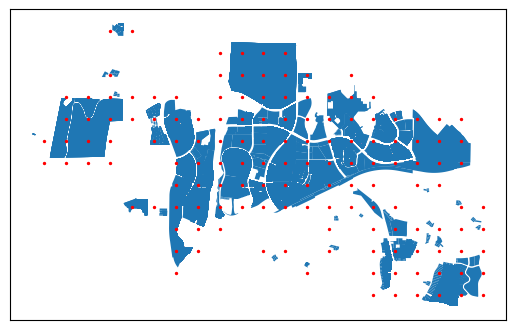

In [11]:
ax = study_land.plot()
grid.centroid.plot(ax=ax, color="red", markersize=2)

ax.set_xticks([])
ax.set_yticks([]);

In [12]:
grid.shape[0]

145

In [ ]:
grid_sample = grid.sample(49, random_state=10)

grid_sample["centroid"] = grid_sample.geometry.centroid
grid_sample = grid_sample[grid_sample["centroid"].notna()]

grid_sample = grid_sample.to_crs(4326)
grid_sample["lon"] = grid_sample.centroid.x
grid_sample["lat"] = grid_sample.centroid.y

## RentCast Feature Collection

Query rental estimates and summarize rent and rent-per-square-foot features.

In [27]:
def compute_features(listings):

    rents = []
    psf = []

    if not isinstance(listings, list):
        return {
            "median_rent": None,
            "median_rent_psq": None,
            "listing_count": 0,
        }

    for listing in listings:

        price = listing.get("price")
        sqft = listing.get("squareFootage")

        if price is None or sqft is None:
            continue
            
        if price < 500 or price > 25000:
            continue

        if sqft < 200 or sqft > 10000:
            continue

        listing_psf = price / sqft

        if listing_psf < 0.5 or listing_psf > 15:
            continue

        rents.append(price)
        psf.append(listing_psf)

    return {
        "median_rent": float(np.median(rents)) if rents else None,
        "median_rent_psq": float(np.median(psf)) if psf else None,
        "listing_count": len(rents),
    }
    

API_KEY = "33dd4367252042e489b44b3d76da947d"

headers = {
    "X-Api-Key": API_KEY,
    "accept": "application/json",
}


def query(lat, lon, radius=0.25):
    url = "https://api.rentcast.io/v1/listings/rental/long-term"

    params = {
        "latitude": lat,
        "longitude": lon,
        "radius": radius,
        "limit": 50,
    }

    try: 
        r = requests.get(url, headers=headers, params=params, timeout=15)

        r.raise_for_status()

        listings = r.json()

        return compute_features(listings)
        
    except Exception as e:
        print(f"Error at ({lat}, {lon}): {e}")

        return {
            "median_rent": None,
            "median_rent_psq": None,
            "listing_count": 0
        }

In [25]:
results_df.to_csv(
    "rent_features.csv",
    index=False
)

In [28]:
rent_gdf.to_file(
    "rent_features.gpkg",
    driver="GPKG"
)

<Axes: >

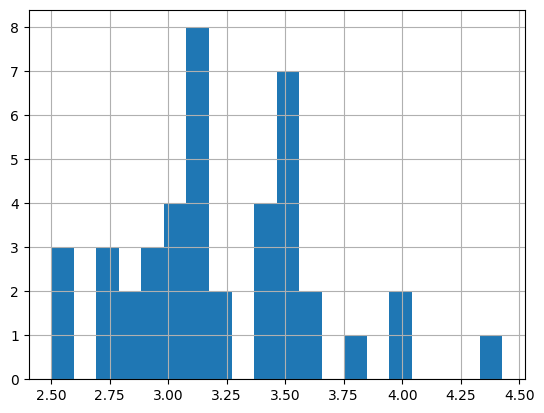

In [36]:
results_df['median_rent_psq'].hist(bins=20)

## Additional Rental Samples

Identify unsampled grid cells and collect additional rental feature batches.

In [11]:
sample1 = pd.read_csv("rent_features.csv")

grid = grid.to_crs(4326)

grid["centroid"] = grid.geometry.centroid
grid["lon"] = grid["centroid"].x
grid["lat"] = grid["centroid"].y

grid["coordinate_id"] = (
    grid["lat"].round(6).astype(str)
    + "_"
    + grid["lon"].round(6).astype(str)
)

sample1["coordinate_id"] = (
    sample1["lat"].round(6).astype(str)
    + "_"
    + sample1["lon"].round(6).astype(str)
)

unsampled = grid[~grid["coordinate_id"].isin(sample1["coordinate_id"])]

In [14]:
unsampled

,geometry,centroid,lon,lat,coordinate_id
6,"POLYGON ((-117.25409 32.8621, -117.25412 32.86...",POINT (-117.25573 32.86346),-117.255730,32.863457,32.863457_-117.25573
20,"POLYGON ((-117.25086 32.86487, -117.25089 32.8...",POINT (-117.2525 32.86623),-117.252505,32.866232,32.866232_-117.252505
21,"POLYGON ((-117.25089 32.86762, -117.25092 32.8...",POINT (-117.25254 32.86898),-117.252536,32.868980,32.86898_-117.252536
22,"POLYGON ((-117.25092 32.87037, -117.25095 32.8...",POINT (-117.25257 32.87173),-117.252568,32.871728,32.871728_-117.252568
32,"POLYGON ((-117.24757 32.86215, -117.2476 32.86...",POINT (-117.24922 32.86351),-117.249217,32.863510,32.86351_-117.249217
...,...,...,...,...,...
250,"POLYGON ((-117.19213 32.85434, -117.19216 32.8...",POINT (-117.19377 32.8557),-117.193769,32.855700,32.8557_-117.193769
260,"POLYGON ((-117.18878 32.84612, -117.18881 32.8...",POINT (-117.19043 32.84748),-117.190425,32.847480,32.84748_-117.190425
262,"POLYGON ((-117.18884 32.85162, -117.18887 32.8...",POINT (-117.19048 32.85298),-117.190484,32.852977,32.852977_-117.190484
263,"POLYGON ((-117.18887 32.85436, -117.1889 32.85...",POINT (-117.19051 32.85573),-117.190513,32.855725,32.855725_-117.190513


In [20]:
sample2 = unsampled.sample(n=50, random_state=10)

results = []

for _, row in sample2.iterrows():

    lat = row["lat"]
    lon = row["lon"]

    features = query(lat, lon)

    results.append({
        "lat": lat,
        "lon": lon,
        **features
    })
    
    time.sleep(1)

results_df = pd.DataFrame(results)

rent_gdf = gpd.GeoDataFrame(
    results_df,
    geometry=gpd.points_from_xy(
        results_df["lon"],
        results_df["lat"]
    ),
    crs=4326
)

In [21]:
results_df

,lat,lon,median_rent,median_rent_psq,listing_count
0,32.860944,-117.226392,3272.5,4.173323,50
1,32.861071,-117.210110,2952.5,3.740119,50
2,32.871728,-117.252568,4500.0,2.317199,1
3,32.863692,-117.226422,3400.0,3.330577,50
4,32.860866,-117.236161,2895.0,3.587629,48
5,32.855600,-117.206794,2870.0,3.411111,50
6,32.852977,-117.190484,4495.0,2.840909,17
7,32.877459,-117.223318,NaN,NaN,0
8,32.871988,-117.220000,3655.0,3.213915,49
9,32.855650,-117.200282,2450.0,3.110245,48


In [22]:
results_df.to_csv(
    "rent_features2.csv",
    index=False
)

rent_gdf.to_file(
    "rent_features2.gpkg",
    driver="GPKG"
)

In [25]:
unsampled = unsampled[~unsampled["coordinate_id"].isin(sample2["coordinate_id"])]
unsampled.shape[0]

46

In [28]:
sample3 = unsampled.sample(n=46, random_state=10)

results = []

for _, row in sample3.iterrows():

    lat = row["lat"]
    lon = row["lon"]

    features = query(lat, lon)

    results.append({
        "lat": lat,
        "lon": lon,
        **features
    })
    
    time.sleep(1)

results_df = pd.DataFrame(results)

rent_gdf = gpd.GeoDataFrame(
    results_df,
    geometry=gpd.points_from_xy(
        results_df["lon"],
        results_df["lat"]
    ),
    crs=4326
)

In [29]:
results_df

,lat,lon,median_rent,median_rent_psq,listing_count
0,32.872090,-117.206973,3340.0,3.089317,50
1,32.869111,-117.236253,3225.0,3.605372,49
2,32.874711,-117.223287,NaN,NaN,0
3,32.858374,-117.203568,2945.0,3.393333,49
4,32.863870,-117.203627,3497.5,3.382590,50
5,32.869417,-117.197173,NaN,NaN,0
6,32.869163,-117.229740,2572.0,3.875000,49
7,32.871781,-117.246054,7400.0,3.229434,6
8,32.850204,-117.193710,4197.5,2.991588,14
9,32.869085,-117.239510,3500.0,3.011551,45


In [30]:
results_df.to_csv(
    "rent_features3.csv",
    index=False
)

rent_gdf.to_file(
    "rent_features3.gpkg",
    driver="GPKG"
)

## Combine Rental Feature Samples

Merge the rental feature batches and remove incomplete observations.

In [33]:
data_1 = pd.read_csv("rent_features1.csv")
data_2 = pd.read_csv("rent_features2.csv")
data_3 = pd.read_csv("rent_features3.csv")

full_rent = pd.concat([data_1, data_2, data_3])
full_rent.shape[0]

145

In [36]:
full_rent = full_rent.dropna()

In [37]:
full_rent.to_csv(
    "full_rent_features.csv",
    index=False
)

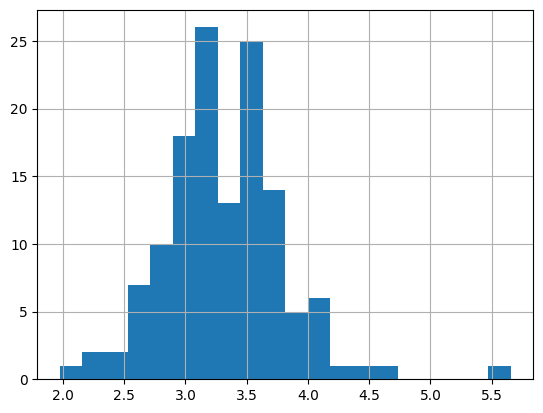

In [38]:
full_rent['median_rent_psq'].hist(bins=20);

In [39]:
full_rent["listing_count"].sum()

np.int64(4924)

## Distance Features

Add distances to major nearby landmarks used as candidate predictors.

In [15]:
full_rent = pd.read_csv("full_rent.csv")

full_rent_features = gpd.GeoDataFrame(
    full_rent,
    geometry=gpd.points_from_xy(full_rent["lon"], full_rent["lat"]),
    crs=4326
)

In [16]:
full_rent_features = full_rent_features.to_crs(2230)

features = gpd.GeoSeries(
    {
        "shores_beach": Point(-117.25693, 32.85800), 
        "utc": Point(-117.21086, 32.87095), 
        "downtown": Point(-117.16450, 32.71880)
    },
    crs=4326
).to_crs(2230)

distances = full_rent_features.geometry.apply(lambda x: features.distance(x))

In [17]:
for column in distances.columns:
    full_rent_features[f"{column}_ft"] = distances[column].round(6)

In [98]:
full_rent_features

,lat,lon,median_rent,median_rent_psq,listing_count,geometry,shores_beach_ft,utc_ft,downtown_ft
0,32.850104,-117.206734,2947.5,2.841849,32,POINT (6267839.915 1890435.568),15680.840376,7689.998749,49506.386061
1,32.863718,-117.223166,2356.0,3.487730,50,POINT (6262839.915 1895435.568),10575.018050,4604.560916,55725.081733
2,32.861147,-117.200341,2995.0,3.531840,50,POINT (6269839.915 1894435.568),17415.346976,4811.947426,52950.806747
3,32.861097,-117.206854,2945.0,3.606719,50,POINT (6267839.915 1894435.568),15418.940484,3790.271635,53385.329164
4,32.852801,-117.213276,4600.0,2.500000,25,POINT (6265839.915 1891435.568),13538.903683,6644.916957,51008.484323
...,...,...,...,...,...,...,...,...,...
128,32.847355,-117.206704,4650.0,2.335069,8,POINT (6267839.915 1889435.568),15903.616324,8679.202796,48539.720679
129,32.863457,-117.255730,9000.0,4.680851,11,POINT (6252839.915 1895435.568),2019.426546,14044.877588,59634.821272
130,32.860918,-117.229648,3512.5,4.225240,46,POINT (6260839.915 1894435.568),8444.920332,6826.842806,55450.089195
131,32.852902,-117.200252,2645.0,3.178065,50,POINT (6269839.915 1891435.568),17504.373231,7330.230508,50014.543918


## OpenStreetMap Amenity Features

Use OSMnx/OpenStreetMap features to compute nearest school, park, and bus stop distances.

In [13]:
import osmnx as osm

tags = {
    "amenity": "school",
    "leisure": "park",
    "highway": "bus_stop"
}

locs = osm.features_from_place("San Diego, California, USA", tags)
locs = locs[locs.geometry.notnull()]
locs["geometry"] = locs["geometry"].centroid
locs = locs.to_crs(2230)

In [100]:
locs

geometry   highway  \
element id                                                      
node    48932353    POINT (6321113.537 1839260.292)  bus_stop   
        49052989    POINT (6280586.018 1840270.114)  bus_stop   
        49097359    POINT (6278511.136 1846395.408)  bus_stop   
        49098926    POINT (6277514.333 1857286.214)  bus_stop   
        49106957    POINT (6293781.521 1849214.549)  bus_stop   
...                                             ...       ...   
way     1508338324  POINT (6291195.169 1851484.768)       NaN   
        1510173990  POINT (6347781.831 1976173.754)       NaN   
        1510431058  POINT (6291043.968 1844658.659)       NaN   
        1510694943  POINT (6266747.138 1916974.085)       NaN   
        1516768817  POINT (6287706.148 1843235.647)       NaN   

                                                            location  \
element id                                                             
node    48932353                    San Vicente And Rytko, San Diego   
        49052989                               G And 01St, San Diego   
        49097359                         India And Kalmia, San Diego   
        49098926    Hotel Circle South And 1333-Kings Inn, San Diego   
        49106957                      Redwood And Gregory, San Diego   
...                                                              ...   
way     1508338324                                               NaN   
        1510173990                                               NaN   
        1510431058                                               NaN   
        1510694943                                               NaN   
        1516768817                                               NaN   

                                                            source  bus  \
element id                                                                
node    48932353    SanDag Public Transit (http://www.sandag.org/)  NaN   
        49052989    SanDag Public Transit (http://www.sandag.org/)  yes   
        49097359    SanDag Public Transit (http://www.sandag.org/)  yes   
        49098926    SanDag Public Transit (http://www.sandag.org/)  yes   
        49106957    SanDag Public Transit (http://www.sandag.org/)  yes   
...                                                            ...  ...   
way     1508338324                                             NaN  NaN   
        1510173990                                             NaN  NaN   
        1510431058                                             NaN  NaN   
        1510694943                                             NaN  NaN   
        1516768817                                             NaN  NaN   

                   public_transport bench  bin shelter  ref  ... name:dih  \
element id                                                   ...            
node    48932353                NaN   NaN  NaN     NaN  NaN  ...      NaN   
        49052989           platform   NaN  NaN     NaN  NaN  ...      NaN   
        49097359           platform   NaN  NaN     NaN  NaN  ...      NaN   
        49098926           platform   NaN  NaN     NaN  NaN  ...      NaN   
        49106957           platform   NaN  NaN     NaN  NaN  ...      NaN   
...                             ...   ...  ...     ...  ...  ...      ...   
way     1508338324              NaN   NaN  NaN     NaN  NaN  ...      NaN   
        1510173990              NaN   NaN  NaN     NaN  NaN  ...      NaN   
        1510431058              NaN   NaN  NaN     NaN  NaN  ...      NaN   
        1510694943              NaN   NaN  NaN     NaN  NaN  ...      NaN   
        1516768817              NaN   NaN  NaN     NaN  NaN  ...      NaN   

                   name:ja garden:type internet_access sidewalk:both landmark  \
element id                                                                      
node    48932353       NaN         NaN             NaN           NaN      NaN   
        49052989       NaN         NaN 

In [18]:
schools = locs[locs["amenity"] == "school"]
parks = locs[locs["leisure"] == "park"]
bus_stops = locs[locs["highway"] == "bus_stop"]

full_rent_features["nearest_school_ft"] = full_rent_features.geometry.apply(
    lambda x: schools.distance(x).min()
)

full_rent_features["nearest_park_ft"] = full_rent_features.geometry.apply(
    lambda x: parks.distance(x).min()
)

full_rent_features["nearest_bus_stop_ft"] = full_rent_features.geometry.apply(
    lambda x: schools.distance(x).min()
)

In [102]:
full_rent_features

,lat,lon,median_rent,median_rent_psq,listing_count,geometry,shores_beach_ft,utc_ft,downtown_ft,nearest_school_ft,nearest_park_ft,nearest_bus_stop_ft
0,32.850104,-117.206734,2947.5,2.841849,32,POINT (6267839.915 1890435.568),15680.840376,7689.998749,49506.386061,1011.028127,788.006465,1011.028127
1,32.863718,-117.223166,2356.0,3.487730,50,POINT (6262839.915 1895435.568),10575.018050,4604.560916,55725.081733,939.894454,1240.946569,939.894454
2,32.861147,-117.200341,2995.0,3.531840,50,POINT (6269839.915 1894435.568),17415.346976,4811.947426,52950.806747,1251.092039,1556.491731,1251.092039
3,32.861097,-117.206854,2945.0,3.606719,50,POINT (6267839.915 1894435.568),15418.940484,3790.271635,53385.329164,761.561734,1121.451834,761.561734
4,32.852801,-117.213276,4600.0,2.500000,25,POINT (6265839.915 1891435.568),13538.903683,6644.916957,51008.484323,1158.761962,1500.046061,1158.761962
...,...,...,...,...,...,...,...,...,...,...,...,...
128,32.847355,-117.206704,4650.0,2.335069,8,POINT (6267839.915 1889435.568),15903.616324,8679.202796,48539.720679,1949.333978,1224.128226,1949.333978
129,32.863457,-117.255730,9000.0,4.680851,11,POINT (6252839.915 1895435.568),2019.426546,14044.877588,59634.821272,3955.854995,1623.479202,3955.854995
130,32.860918,-117.229648,3512.5,4.225240,46,POINT (6260839.915 1894435.568),8444.920332,6826.842806,55450.089195,2890.379668,715.485771,2890.379668
131,32.852902,-117.200252,2645.0,3.178065,50,POINT (6269839.915 1891435.568),17504.373231,7330.230508,50014.543918,1006.479197,2844.476604,1006.479197


## Final Processed Dataset

Export the processed dataset used by the regression notebooks.

In [103]:
full_rent_features = full_rent_features.drop(columns=["geometry"])

full_rent_features.to_csv(
    "full_rent_features.csv",
    index=False
)

In [20]:
full_rent_features["listing_count"].sum()

np.int64(4924)